In [9]:
from pathlib import Path
import sys

def find_project_root():
    here = Path.cwd()
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from utils.data_loading import load_data as load_v1_original
from utils.data_loadingV2 import load_data as load_v2_temporal
from utils.data_loadingV3_random import load_data as load_v3_random
from utils.data_loadingV4_file import load_data as load_v4_file
from utils.simple_lds_loss import SimpleLDSLoss

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

In [11]:
CONFIG = {
    'TRAIN_PATH': r'../datasets_challenge/train',
    'VAL_RATIO': 0.2,
    'BATCH_SIZE': 128,
    'COLUMNS_TO_DROP': ['sideSlip', 'vyCG', 'longitude', 'latitude', 'time'],
    'SEQUENCE_LENGTH': 20,
    'THRESHOLD': True,
    'THRESHOLD_VALUE': 3.0,
    'THRESHOLD_COLUMN': 'vxCG',
    'TARGET': 'sideSlip',
    'SCALING': True,
    'SEED': 42,
    'NUM_BINS': 100,
    'DIST_CSV': r'../datasets_challenge/sideSlip_distribution.csv',
}

In [12]:
print("Loading V1: Original Split")
train_v1, val_v1, pipeline_v1 = load_v1_original(
    train_path=CONFIG['TRAIN_PATH'],
    train_ratio=0.8,
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold=CONFIG['THRESHOLD'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    batchsize=CONFIG['BATCH_SIZE'],
    seed=CONFIG['SEED']
)

print("\nLoading V2: Temporal Split")
train_v2, val_v2, scaler_v2, _, _ = load_v2_temporal(
    train_path=CONFIG['TRAIN_PATH'],
    val_ratio=0.15,
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    batchsize=CONFIG['BATCH_SIZE'],
    seed=CONFIG['SEED']
)

print("\nLoading V3: Random Split")
train_v3, val_v3, scaler_v3, _, _ = load_v3_random(
    train_path=CONFIG['TRAIN_PATH'],
    val_ratio=0.2,
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    batchsize=CONFIG['BATCH_SIZE'],
    seed=CONFIG['SEED']
)

print("\nLoading V4: File-Based Split (File 7)")
train_v4, val_v4, scaler_v4, _, _ = load_v4_file(
    train_path=CONFIG['TRAIN_PATH'],
    val_file_num=7,
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    batchsize=CONFIG['BATCH_SIZE'],
    seed=CONFIG['SEED']
)

def extract_targets(loader):
    targets = []
    for _, y in loader:
        targets.append(y)
    return torch.cat(targets).numpy().flatten()

train_targets_v1 = extract_targets(train_v1)
val_targets_v1 = extract_targets(val_v1)

train_targets_v2 = extract_targets(train_v2)
val_targets_v2 = extract_targets(val_v2)

train_targets_v3 = extract_targets(train_v3)
val_targets_v3 = extract_targets(val_v3)

train_targets_v4 = extract_targets(train_v4)
val_targets_v4 = extract_targets(val_v4)

print(f"\nDataset Sizes:")
print(f"V1 Original: Train {len(train_targets_v1):,} | Val {len(val_targets_v1):,}")
print(f"V2 Temporal: Train {len(train_targets_v2):,} | Val {len(val_targets_v2):,}")
print(f"V3 Random:   Train {len(train_targets_v3):,} | Val {len(val_targets_v3):,}")
print(f"V4 File:     Train {len(train_targets_v4):,} | Val {len(val_targets_v4):,}")

Loading V1: Original Split
../datasets_challenge/train/train_part_001.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge/train/train_part_012.csv
../datasets_challenge/train/train_part_013.csv
../datasets_challenge/train/train_part_014.csv
../datasets_challenge/train/train_part_015.csv
../datasets_challenge/train/train_part_016.csv
../datasets_challenge/train/train_part_017.csv
../datasets_challenge/train/train_part_018.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train

## 1. Target Distribution Analysis - All Dataloaders

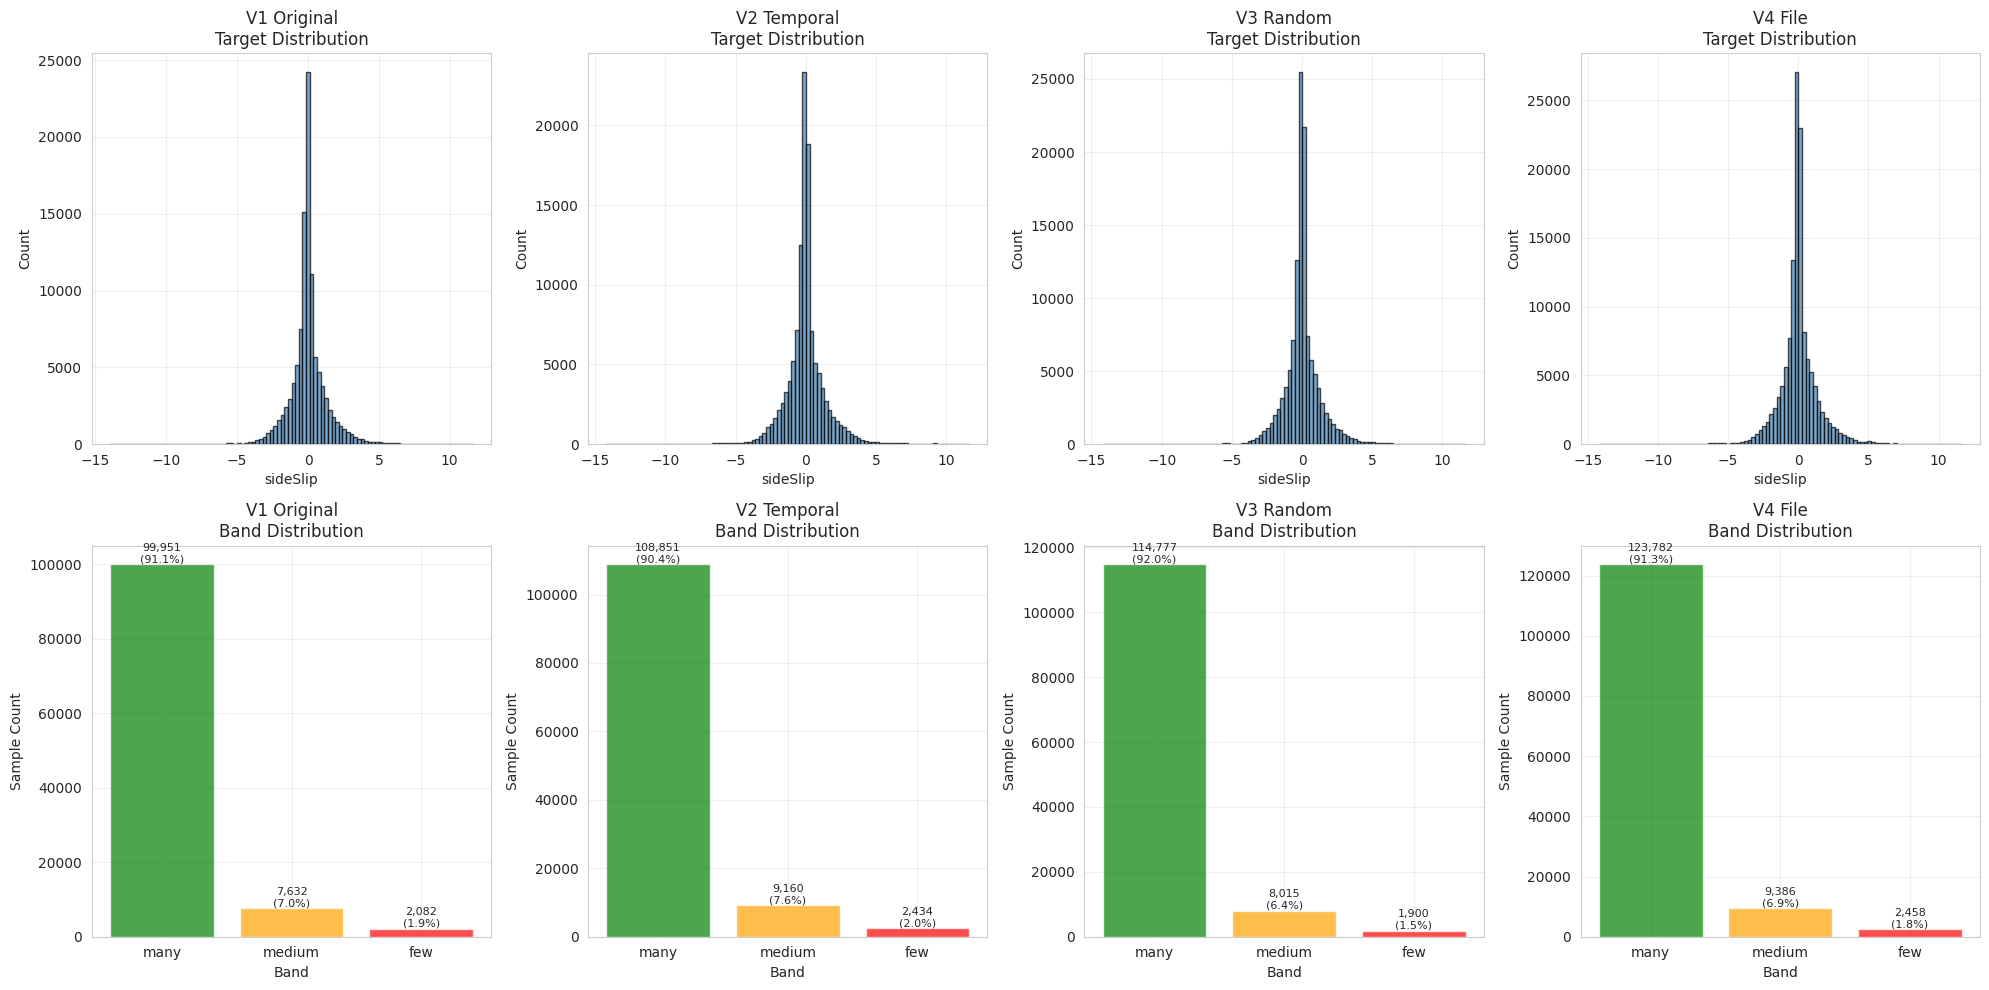


Band Statistics Comparison:

V1 Original:
  many    : 99,951 samples (91.14%)
  medium  :  7,632 samples ( 6.96%)
  few     :  2,082 samples ( 1.90%)

V2 Temporal:
  many    : 108,851 samples (90.37%)
  medium  :  9,160 samples ( 7.61%)
  few     :  2,434 samples ( 2.02%)

V3 Random:
  many    : 114,777 samples (92.05%)
  medium  :  8,015 samples ( 6.43%)
  few     :  1,900 samples ( 1.52%)

V4 File:
  many    : 123,782 samples (91.27%)
  medium  :  9,386 samples ( 6.92%)
  few     :  2,458 samples ( 1.81%)


In [13]:
dist_df = pd.read_csv(CONFIG['DIST_CSV'])
band_dict = dict(zip(dist_df['sideSlip'].values, dist_df['band'].values))

def get_band_counts(targets):
    bands = [band_dict.get(round(float(val), 1), 'unknown') for val in targets]
    return pd.Series(bands).value_counts(), bands

band_counts_v1, bands_v1 = get_band_counts(train_targets_v1)
band_counts_v2, bands_v2 = get_band_counts(train_targets_v2)
band_counts_v3, bands_v3 = get_band_counts(train_targets_v3)
band_counts_v4, bands_v4 = get_band_counts(train_targets_v4)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

loaders = [
    ('V1 Original', train_targets_v1, band_counts_v1, bands_v1),
    ('V2 Temporal', train_targets_v2, band_counts_v2, bands_v2),
    ('V3 Random', train_targets_v3, band_counts_v3, bands_v3),
    ('V4 File', train_targets_v4, band_counts_v4, bands_v4)
]

for i, (name, targets, counts, bands) in enumerate(loaders):
    axes[0, i].hist(targets, bins=100, color='steelblue', alpha=0.7, edgecolor='black')
    axes[0, i].set_xlabel('sideSlip')
    axes[0, i].set_ylabel('Count')
    axes[0, i].set_title(f'{name}\nTarget Distribution')
    axes[0, i].grid(True, alpha=0.3)
    
    axes[1, i].bar(counts.index, counts.values, color=['green', 'orange', 'red'], alpha=0.7)
    axes[1, i].set_xlabel('Band')
    axes[1, i].set_ylabel('Sample Count')
    axes[1, i].set_title(f'{name}\nBand Distribution')
    axes[1, i].grid(True, alpha=0.3)
    for j, (band, count) in enumerate(counts.items()):
        axes[1, i].text(j, count, f"{count:,}\n({100*count/len(bands):.1f}%)", 
                       ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

print("\nBand Statistics Comparison:")
print("="*80)
for name, _, counts, bands in loaders:
    print(f"\n{name}:")
    for band in ['many', 'medium', 'few']:
        count = counts.get(band, 0)
        pct = 100 * count / len(bands)
        print(f"  {band:8s}: {count:6,} samples ({pct:5.2f}%)")

## 2. LDS Weight Analysis - All Dataloaders

✅ LDS enabled: gaussian kernel (ks=5, sigma=2)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.021, 5.437]
Weight mean: 1.000 (normalized to 1.0)

✅ LDS enabled: gaussian kernel (ks=5, sigma=2)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.021, 5.689]
Weight mean: 1.000 (normalized to 1.0)

✅ LDS enabled: gaussian kernel (ks=5, sigma=2)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.020, 5.589]
Weight mean: 1.000 (normalized to 1.0)

✅ LDS enabled: gaussian kernel (ks=5, sigma=2)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.019, 5.661]
Weight mean: 1.000 (normalized to 1.0)



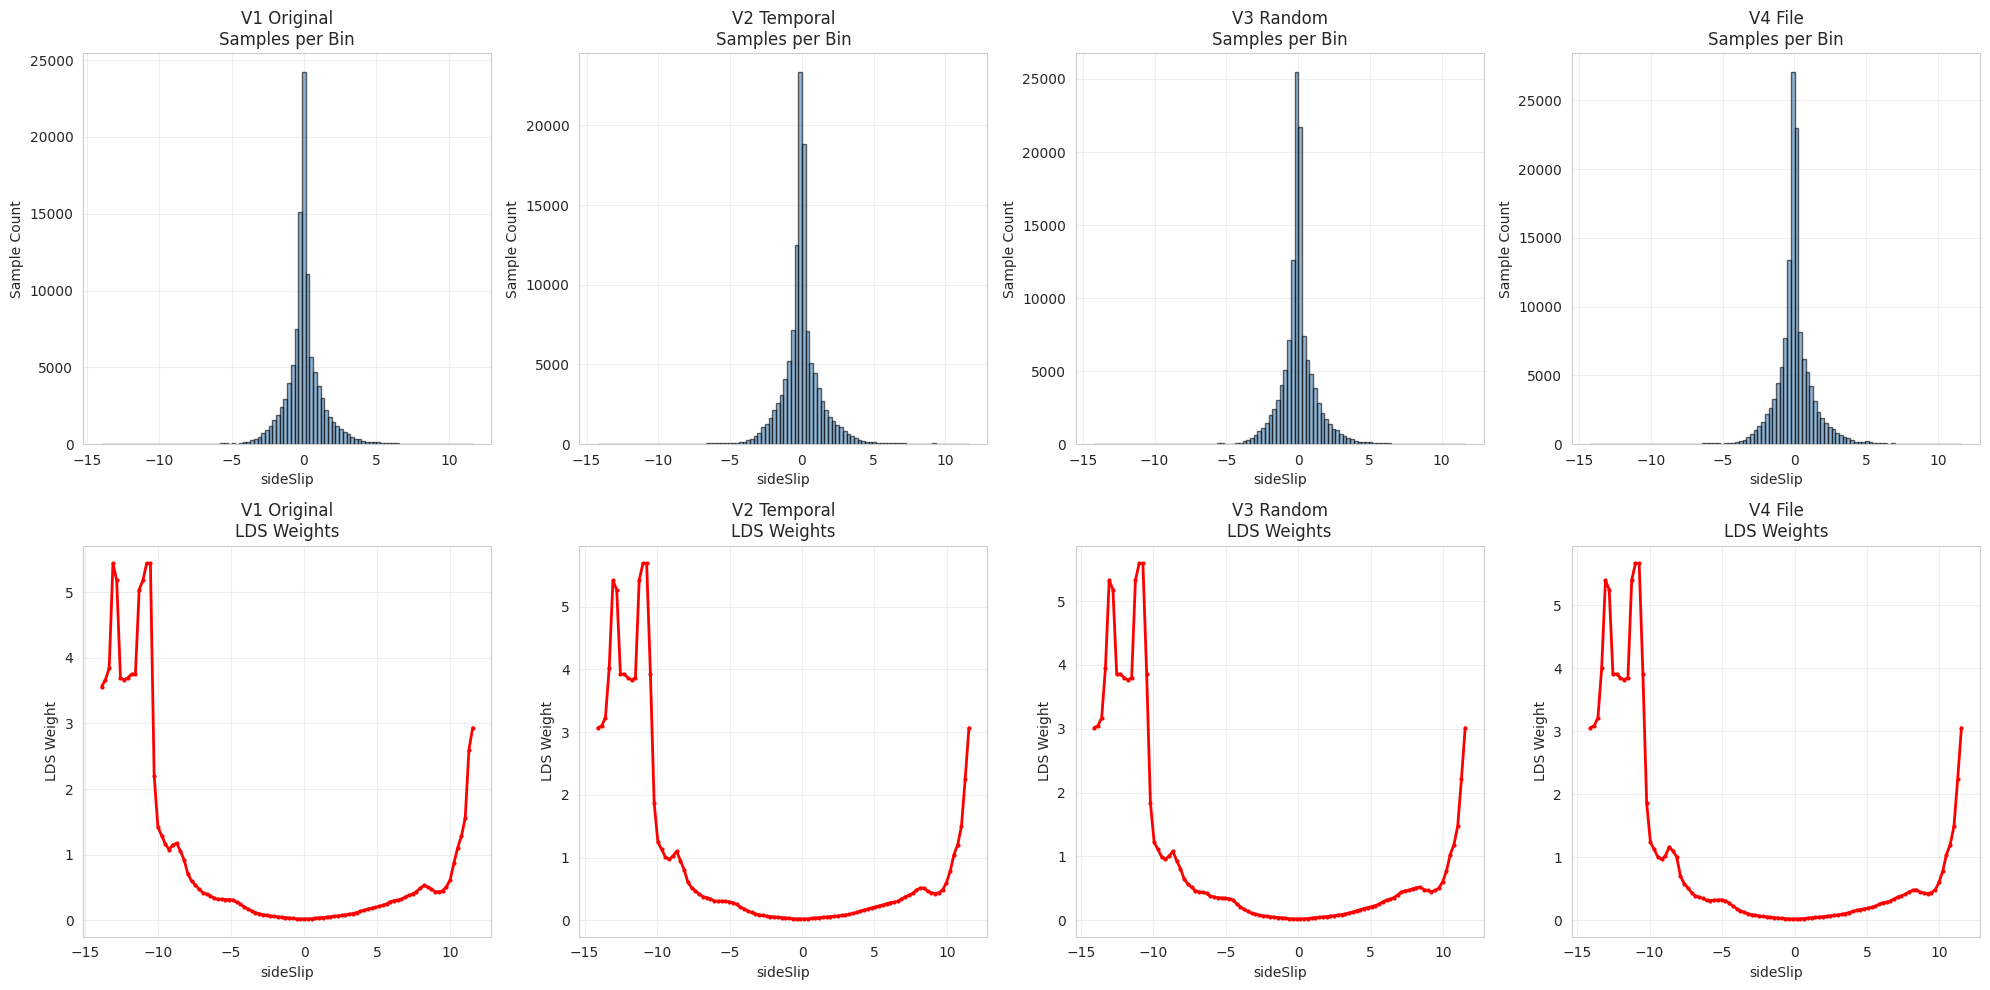


LDS Weight Statistics Comparison:

V1 Original:
  Min weight: 0.0205
  Max weight: 5.4373
  Mean weight: 1.0000
  Weight range: 265.19x

V2 Temporal:
  Min weight: 0.0206
  Max weight: 5.6894
  Mean weight: 1.0000
  Weight range: 275.57x

V3 Random:
  Min weight: 0.0195
  Max weight: 5.5892
  Mean weight: 1.0000
  Weight range: 286.34x

V4 File:
  Min weight: 0.0191
  Max weight: 5.6608
  Mean weight: 1.0000
  Weight range: 295.88x


In [14]:
def create_lds_criterion(targets):
    return SimpleLDSLoss(
        train_targets=targets,
        base='smoothl1',
        smoothl1_beta=0.1,
        reweight='sqrt_inv',
        lds=True,
        lds_kernel='gaussian',
        lds_ks=5,
        lds_sigma=2,
        num_bins=CONFIG['NUM_BINS']
    )

criterion_v1 = create_lds_criterion(train_targets_v1)
criterion_v2 = create_lds_criterion(train_targets_v2)
criterion_v3 = create_lds_criterion(train_targets_v3)
criterion_v4 = create_lds_criterion(train_targets_v4)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

criterions = [
    ('V1 Original', criterion_v1, train_targets_v1),
    ('V2 Temporal', criterion_v2, train_targets_v2),
    ('V3 Random', criterion_v3, train_targets_v3),
    ('V4 File', criterion_v4, train_targets_v4)
]

for i, (name, crit, targets) in enumerate(criterions):
    weights = crit.weights.cpu().numpy()
    bin_edges = crit.bin_edges.cpu().numpy()
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    hist_counts, _ = np.histogram(targets, bins=bin_edges)
    
    axes[0, i].bar(bin_centers, hist_counts, width=np.diff(bin_edges), 
                   color='steelblue', alpha=0.6, edgecolor='black')
    axes[0, i].set_xlabel('sideSlip')
    axes[0, i].set_ylabel('Sample Count')
    axes[0, i].set_title(f'{name}\nSamples per Bin')
    axes[0, i].grid(True, alpha=0.3)
    
    axes[1, i].plot(bin_centers, weights, color='red', linewidth=2, marker='o', markersize=2)
    axes[1, i].set_xlabel('sideSlip')
    axes[1, i].set_ylabel('LDS Weight')
    axes[1, i].set_title(f'{name}\nLDS Weights')
    axes[1, i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nLDS Weight Statistics Comparison:")
print("="*80)
for name, crit, _ in criterions:
    weights = crit.weights.cpu().numpy()
    print(f"\n{name}:")
    print(f"  Min weight: {weights.min():.4f}")
    print(f"  Max weight: {weights.max():.4f}")
    print(f"  Mean weight: {weights.mean():.4f}")
    print(f"  Weight range: {weights.max() / weights.min():.2f}x")

## 3. Feature Statistics by Band - All Dataloaders

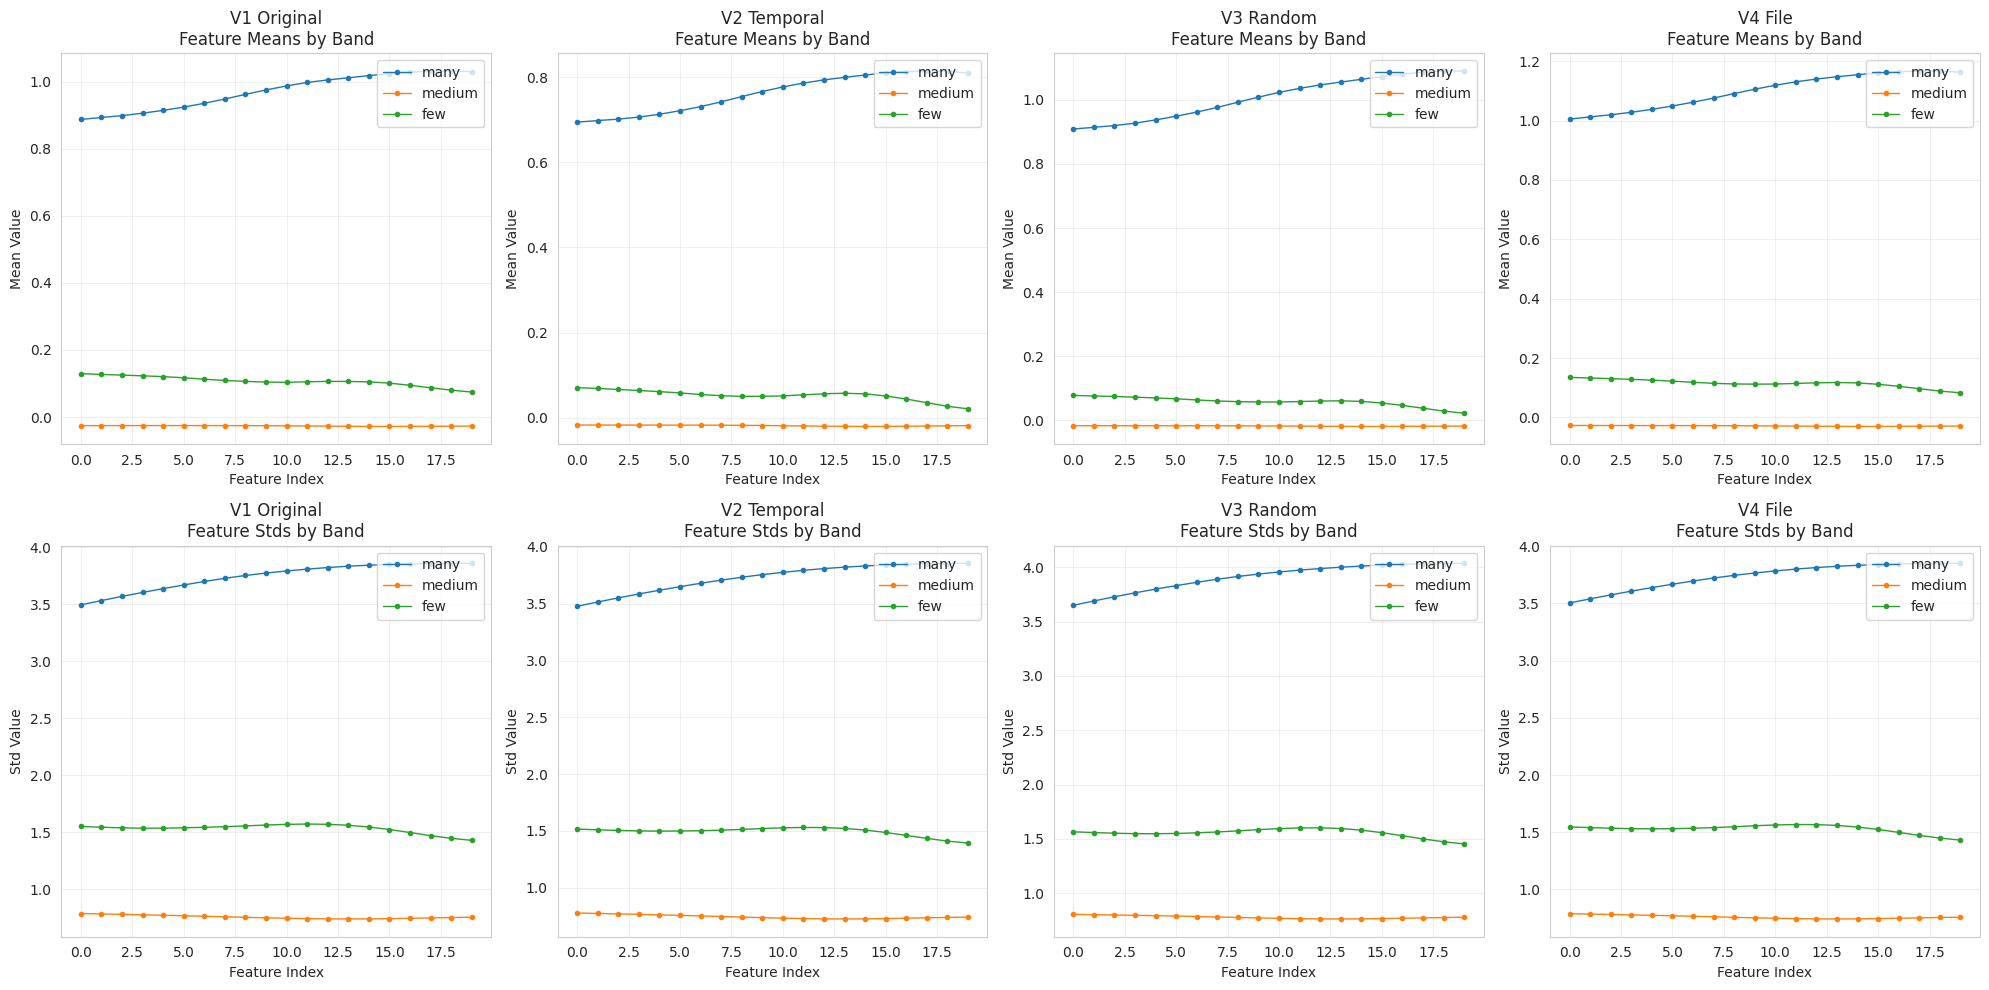


Feature Statistics Comparison:

V1 Original:
  Mean range: -0.0280 to 1.0321
  Std range: 0.7388 to 3.8568

V2 Temporal:
  Mean range: -0.0206 to 0.8146
  Std range: 0.7243 to 3.8554

V3 Random:
  Mean range: -0.0194 to 1.0905
  Std range: 0.7635 to 4.0351

V4 File:
  Mean range: -0.0303 to 1.1675
  Std range: 0.7425 to 3.8492


In [7]:
def compute_feature_stats_by_band(loader, targets):
    all_X = []
    all_y = []
    for X, y in loader:
        all_X.append(X)
        all_y.append(y)
    
    X = torch.cat(all_X, dim=0)
    y_targets = torch.cat(all_y).numpy().flatten()
    X_features = X[:, :, 0].numpy()
    
    bands = [band_dict.get(round(float(val), 1), 'unknown') for val in y_targets]
    df_features = pd.DataFrame(X_features)
    df_features['band'] = bands
    
    feature_means = df_features.groupby('band').mean()
    feature_stds = df_features.groupby('band').std()
    
    return feature_means, feature_stds

means_v1, stds_v1 = compute_feature_stats_by_band(train_v1, train_targets_v1)
means_v2, stds_v2 = compute_feature_stats_by_band(train_v2, train_targets_v2)
means_v3, stds_v3 = compute_feature_stats_by_band(train_v3, train_targets_v3)
means_v4, stds_v4 = compute_feature_stats_by_band(train_v4, train_targets_v4)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

feature_stats = [
    ('V1 Original', means_v1, stds_v1),
    ('V2 Temporal', means_v2, stds_v2),
    ('V3 Random', means_v3, stds_v3),
    ('V4 File', means_v4, stds_v4)
]

for i, (name, means, stds) in enumerate(feature_stats):
    axes[0, i].plot(means.T.values, marker='o', linewidth=1, markersize=3)
    axes[0, i].set_title(f'{name}\nFeature Means by Band')
    axes[0, i].set_xlabel('Feature Index')
    axes[0, i].set_ylabel('Mean Value')
    axes[0, i].legend(['many', 'medium', 'few'], loc='upper right')
    axes[0, i].grid(True, alpha=0.3)
    
    axes[1, i].plot(stds.T.values, marker='o', linewidth=1, markersize=3)
    axes[1, i].set_title(f'{name}\nFeature Stds by Band')
    axes[1, i].set_xlabel('Feature Index')
    axes[1, i].set_ylabel('Std Value')
    axes[1, i].legend(['many', 'medium', 'few'], loc='upper right')
    axes[1, i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nFeature Statistics Comparison:")
print("="*80)
for name, means, stds in feature_stats:
    print(f"\n{name}:")
    print(f"  Mean range: {means.min().min():.4f} to {means.max().max():.4f}")
    print(f"  Std range: {stds.min().min():.4f} to {stds.max().max():.4f}")

## 4. Train vs Val Split Quality - All Dataloaders

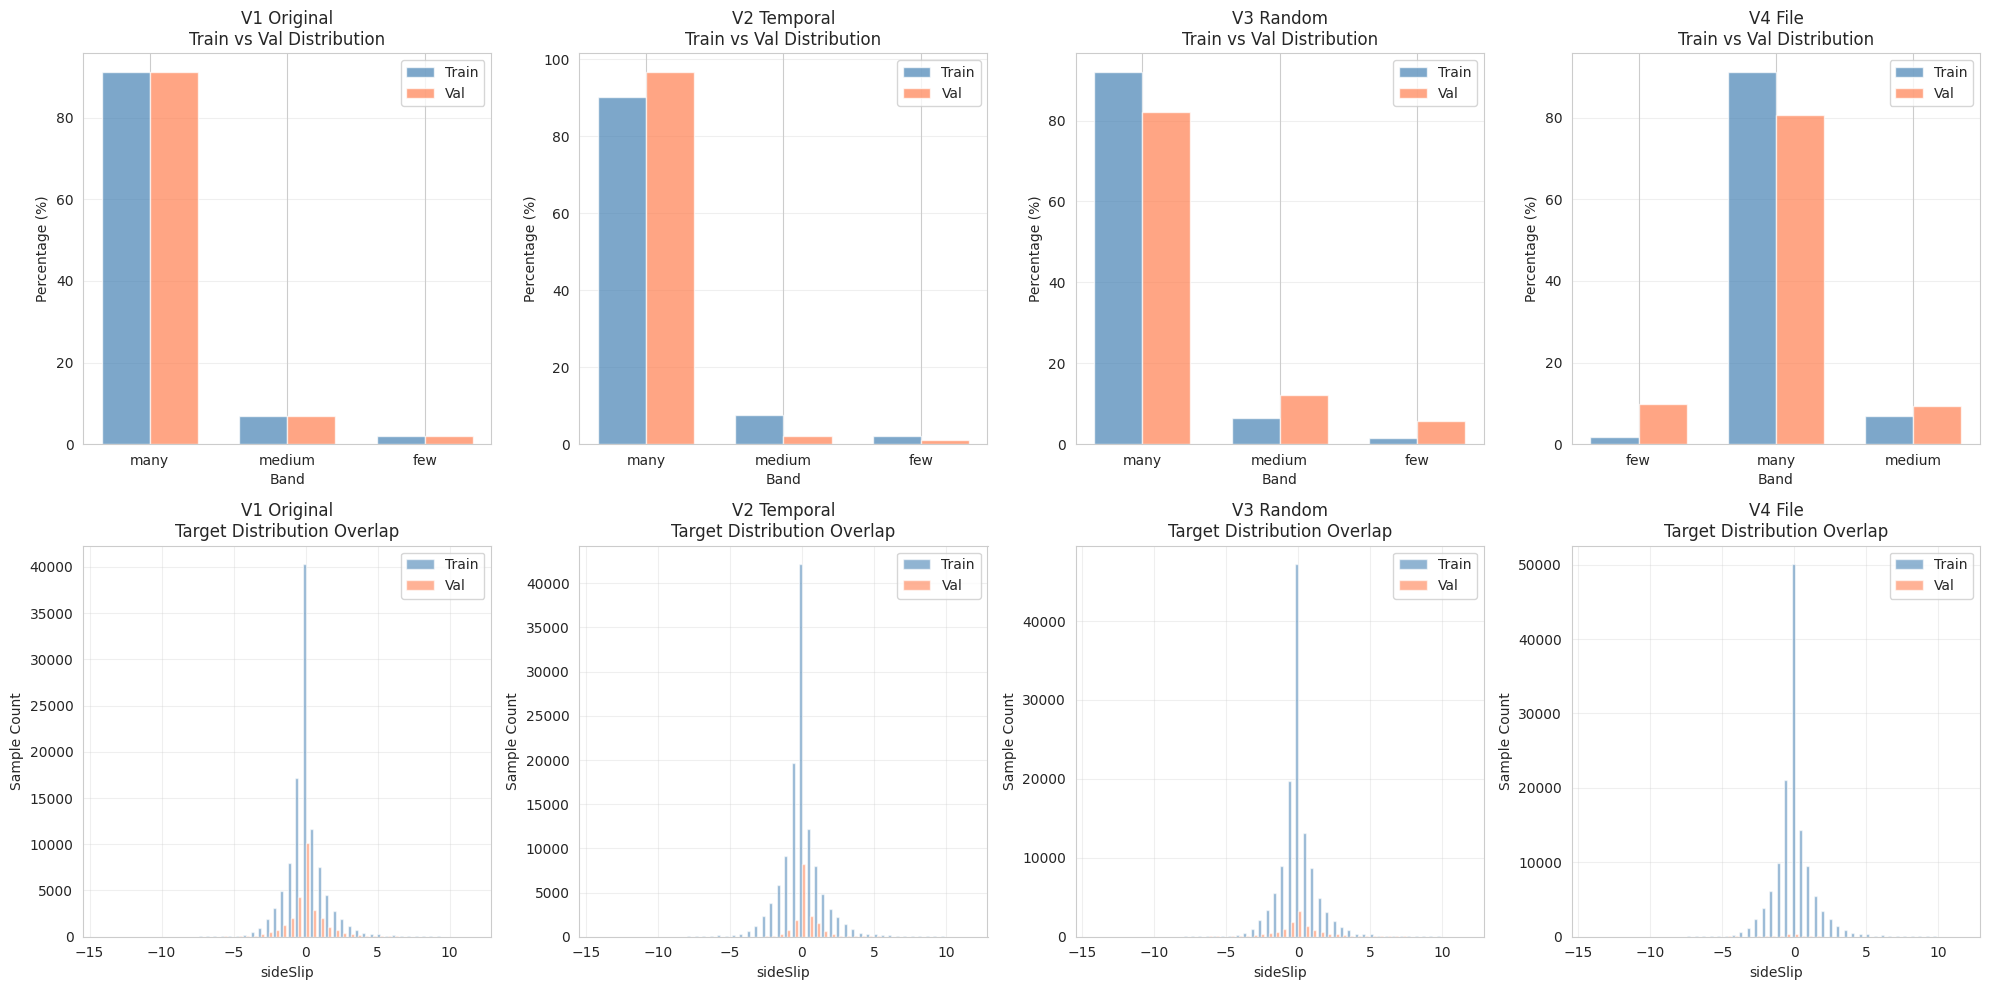


Split Quality Comparison:

V1 Original:
        train_pct    val_pct  pct_diff
many    91.142115  91.209192  0.067077
medium   6.959376   6.890388  0.068988
few      1.898509   1.900419  0.001910
  Max percentage diff: 0.07%

V2 Temporal:
        train_pct    val_pct  pct_diff
many    90.374030  96.813946  6.439917
medium   7.605131   2.170123  5.435008
few      2.020839   1.015930  1.004909
  Max percentage diff: 6.44%

V3 Random:
        train_pct    val_pct  pct_diff
many    92.048407  82.168227  9.880180
medium   6.427838  12.156926  5.729088
few      1.523755   5.674847  4.151092
  Max percentage diff: 9.88%

V4 File:
        train_pct    val_pct   pct_diff
few      1.812337   9.972490   8.160153
many    91.267161  80.742779  10.524383
medium   6.920502   9.284732   2.364230
  Max percentage diff: 10.52%


In [8]:
def analyze_split_quality(train_targets, val_targets):
    train_bands = [band_dict.get(round(float(val), 1), 'unknown') for val in train_targets]
    val_bands = [band_dict.get(round(float(val), 1), 'unknown') for val in val_targets]
    
    train_band_counts = pd.Series(train_bands).value_counts()
    val_band_counts = pd.Series(val_bands).value_counts()
    
    dist_df = pd.DataFrame({
        'train_count': train_band_counts,
        'val_count': val_band_counts
    }).fillna(0)
    
    dist_df['train_pct'] = 100 * dist_df['train_count'] / dist_df['train_count'].sum()
    dist_df['val_pct'] = 100 * dist_df['val_count'] / dist_df['val_count'].sum()
    dist_df['pct_diff'] = abs(dist_df['train_pct'] - dist_df['val_pct'])
    
    return dist_df, train_bands, val_bands

dist_v1, train_bands_v1, val_bands_v1 = analyze_split_quality(train_targets_v1, val_targets_v1)
dist_v2, train_bands_v2, val_bands_v2 = analyze_split_quality(train_targets_v2, val_targets_v2)
dist_v3, train_bands_v3, val_bands_v3 = analyze_split_quality(train_targets_v3, val_targets_v3)
dist_v4, train_bands_v4, val_bands_v4 = analyze_split_quality(train_targets_v4, val_targets_v4)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

split_data = [
    ('V1 Original', dist_v1, train_bands_v1, val_bands_v1, train_targets_v1, val_targets_v1),
    ('V2 Temporal', dist_v2, train_bands_v2, val_bands_v2, train_targets_v2, val_targets_v2),
    ('V3 Random', dist_v3, train_bands_v3, val_bands_v3, train_targets_v3, val_targets_v3),
    ('V4 File', dist_v4, train_bands_v4, val_bands_v4, train_targets_v4, val_targets_v4)
]

for i, (name, dist, train_bands, val_bands, train_tgt, val_tgt) in enumerate(split_data):
    x = np.arange(len(dist))
    width = 0.35
    
    axes[0, i].bar(x - width/2, dist['train_pct'], width, label='Train', color='steelblue', alpha=0.7)
    axes[0, i].bar(x + width/2, dist['val_pct'], width, label='Val', color='coral', alpha=0.7)
    axes[0, i].set_xlabel('Band')
    axes[0, i].set_ylabel('Percentage (%)')
    axes[0, i].set_title(f'{name}\nTrain vs Val Distribution')
    axes[0, i].set_xticks(x)
    axes[0, i].set_xticklabels(dist.index)
    axes[0, i].legend()
    axes[0, i].grid(True, alpha=0.3, axis='y')
    
    axes[1, i].hist([train_tgt, val_tgt], bins=50, alpha=0.6, label=['Train', 'Val'], 
                    color=['steelblue', 'coral'])
    axes[1, i].set_xlabel('sideSlip')
    axes[1, i].set_ylabel('Sample Count')
    axes[1, i].set_title(f'{name}\nTarget Distribution Overlap')
    axes[1, i].legend()
    axes[1, i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSplit Quality Comparison:")
print("="*80)
for name, dist, _, _, _, _ in split_data:
    print(f"\n{name}:")
    print(dist[['train_pct', 'val_pct', 'pct_diff']])
    print(f"  Max percentage diff: {dist['pct_diff'].max():.2f}%")

## 5. LDS vs No-LDS Comparison - All Dataloaders

ℹ️  LDS disabled: using empirical distribution

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.000, 8.320]
Weight mean: 1.000 (normalized to 1.0)

ℹ️  LDS disabled: using empirical distribution

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.000, 9.075]
Weight mean: 1.000 (normalized to 1.0)

ℹ️  LDS disabled: using empirical distribution

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.000, 9.074]
Weight mean: 1.000 (normalized to 1.0)

ℹ️  LDS disabled: using empirical distribution

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.000, 9.075]
Weight mean: 1.000 (normalized to 1.0)



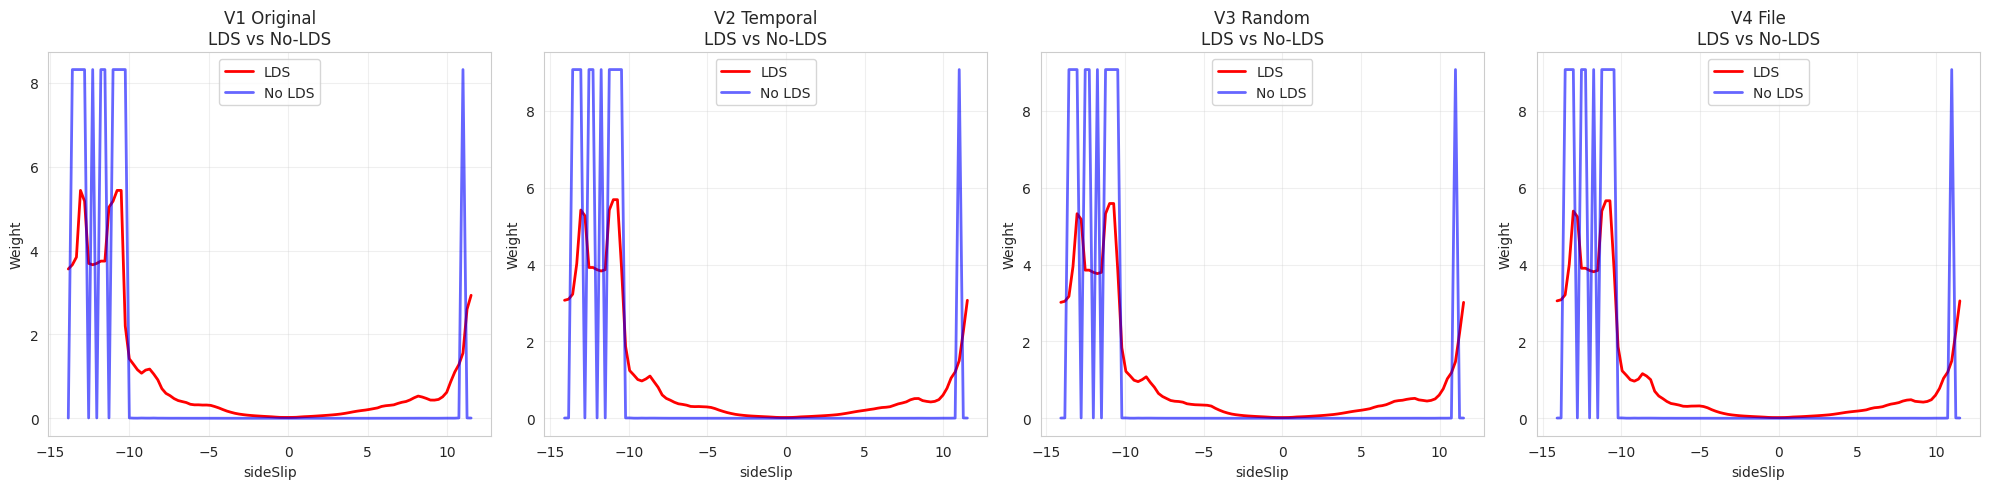


LDS vs No-LDS Smoothing Comparison:

V1 Original:
  No-LDS weight range: 155714.50x
  LDS weight range: 265.19x
  Smoothing factor: 587.19x
  Mean weight difference: 1.0148

V2 Temporal:
  No-LDS weight range: 152829.97x
  LDS weight range: 275.57x
  Smoothing factor: 554.59x
  Mean weight difference: 1.0650

V3 Random:
  No-LDS weight range: 159665.27x
  LDS weight range: 286.34x
  Smoothing factor: 557.61x
  Mean weight difference: 1.0812

V4 File:
  No-LDS weight range: 164550.91x
  LDS weight range: 295.88x
  Smoothing factor: 556.15x
  Mean weight difference: 1.0696


In [15]:
def create_no_lds_criterion(targets):
    return SimpleLDSLoss(
        train_targets=targets,
        base='smoothl1',
        smoothl1_beta=0.1,
        reweight='sqrt_inv',
        lds=False,
        num_bins=CONFIG['NUM_BINS']
    )

criterion_no_lds_v1 = create_no_lds_criterion(train_targets_v1)
criterion_no_lds_v2 = create_no_lds_criterion(train_targets_v2)
criterion_no_lds_v3 = create_no_lds_criterion(train_targets_v3)
criterion_no_lds_v4 = create_no_lds_criterion(train_targets_v4)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

comparison_data = [
    ('V1 Original', criterion_v1, criterion_no_lds_v1),
    ('V2 Temporal', criterion_v2, criterion_no_lds_v2),
    ('V3 Random', criterion_v3, criterion_no_lds_v3),
    ('V4 File', criterion_v4, criterion_no_lds_v4)
]

for i, (name, crit_lds, crit_no_lds) in enumerate(comparison_data):
    weights_lds = crit_lds.weights.cpu().numpy()
    weights_no_lds = crit_no_lds.weights.cpu().numpy()
    bin_edges = crit_lds.bin_edges.cpu().numpy()
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    axes[i].plot(bin_centers, weights_lds, label='LDS', color='red', linewidth=2)
    axes[i].plot(bin_centers, weights_no_lds, label='No LDS', color='blue', linewidth=2, alpha=0.6)
    axes[i].set_xlabel('sideSlip')
    axes[i].set_ylabel('Weight')
    axes[i].set_title(f'{name}\nLDS vs No-LDS')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nLDS vs No-LDS Smoothing Comparison:")
print("="*80)
for name, crit_lds, crit_no_lds in comparison_data:
    weights_lds = crit_lds.weights.cpu().numpy()
    weights_no_lds = crit_no_lds.weights.cpu().numpy()
    weight_diff = np.abs(weights_lds - weights_no_lds).mean()
    
    print(f"\n{name}:")
    print(f"  No-LDS weight range: {weights_no_lds.max() / weights_no_lds.min():.2f}x")
    print(f"  LDS weight range: {weights_lds.max() / weights_lds.min():.2f}x")
    print(f"  Smoothing factor: {(weights_no_lds.max() / weights_no_lds.min()) / (weights_lds.max() / weights_lds.min()):.2f}x")
    print(f"  Mean weight difference: {weight_diff:.4f}")

## 6. FDS Bin Analysis - All Dataloaders

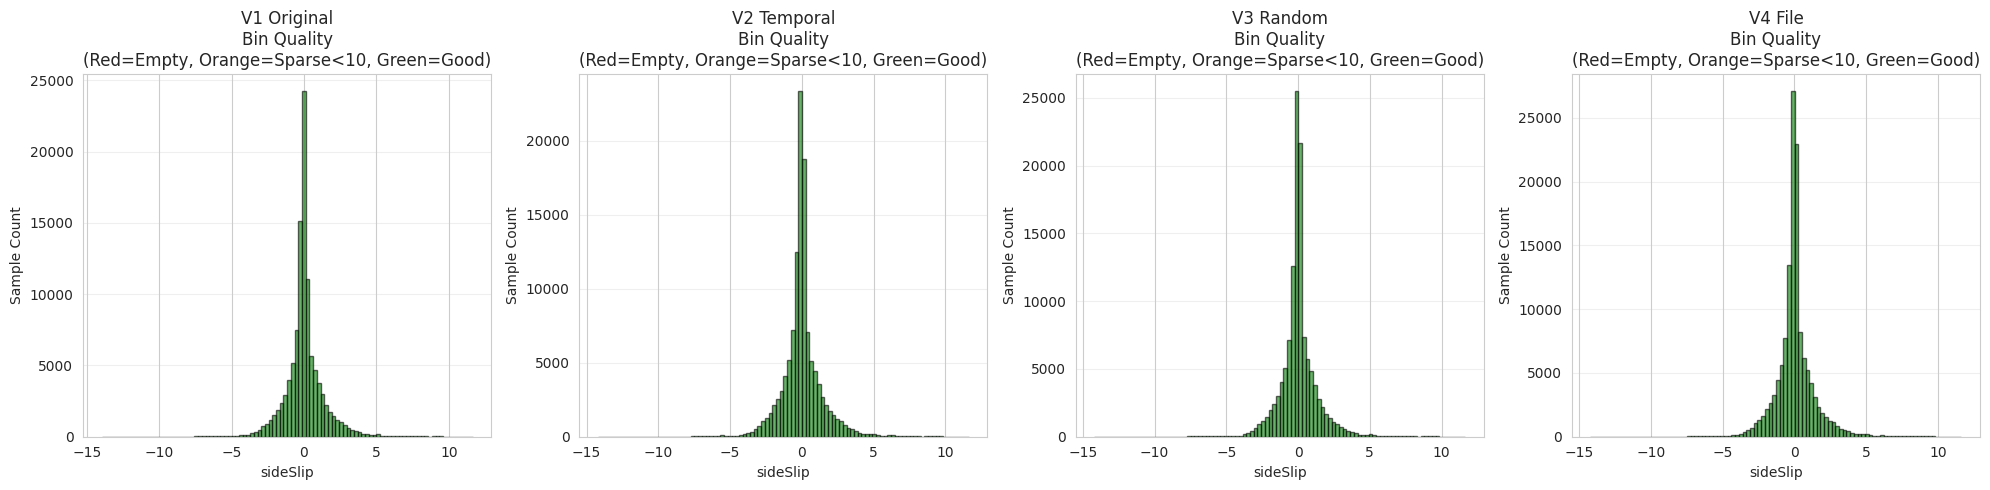


FDS Bin Quality Comparison:

V1 Original:
  Total bins: 100
  Empty bins: 12 (12.0%)
  Sparse bins (<10): 19 (19.0%)
  Good bins: 69 (69.0%)

V2 Temporal:
  Total bins: 100
  Empty bins: 11 (11.0%)
  Sparse bins (<10): 19 (19.0%)
  Good bins: 70 (70.0%)

V3 Random:
  Total bins: 100
  Empty bins: 11 (11.0%)
  Sparse bins (<10): 19 (19.0%)
  Good bins: 70 (70.0%)

V4 File:
  Total bins: 100
  Empty bins: 11 (11.0%)
  Sparse bins (<10): 20 (20.0%)
  Good bins: 69 (69.0%)


In [16]:
def analyze_fds_bins(criterion, targets):
    bin_edges = criterion.bin_edges.cpu().numpy()
    hist_counts, _ = np.histogram(targets, bins=bin_edges)
    bin_assignments = np.digitize(targets, bin_edges) - 1
    
    empty_bins = np.where(hist_counts == 0)[0]
    sparse_bins = np.where((hist_counts > 0) & (hist_counts < 10))[0]
    
    return hist_counts, empty_bins, sparse_bins, bin_edges

counts_v1, empty_v1, sparse_v1, edges_v1 = analyze_fds_bins(criterion_v1, train_targets_v1)
counts_v2, empty_v2, sparse_v2, edges_v2 = analyze_fds_bins(criterion_v2, train_targets_v2)
counts_v3, empty_v3, sparse_v3, edges_v3 = analyze_fds_bins(criterion_v3, train_targets_v3)
counts_v4, empty_v4, sparse_v4, edges_v4 = analyze_fds_bins(criterion_v4, train_targets_v4)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

bin_analysis = [
    ('V1 Original', counts_v1, empty_v1, sparse_v1, edges_v1),
    ('V2 Temporal', counts_v2, empty_v2, sparse_v2, edges_v2),
    ('V3 Random', counts_v3, empty_v3, sparse_v3, edges_v3),
    ('V4 File', counts_v4, empty_v4, sparse_v4, edges_v4)
]

for i, (name, counts, empty, sparse, edges) in enumerate(bin_analysis):
    bin_centers = (edges[:-1] + edges[1:]) / 2
    colors = ['red' if j in empty else 'orange' if j in sparse else 'green' 
              for j in range(len(counts))]
    
    axes[i].bar(bin_centers, counts, width=np.diff(edges), color=colors, alpha=0.6, edgecolor='black')
    axes[i].set_xlabel('sideSlip')
    axes[i].set_ylabel('Sample Count')
    axes[i].set_title(f'{name}\nBin Quality\n(Red=Empty, Orange=Sparse<10, Green=Good)')
    axes[i].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\nFDS Bin Quality Comparison:")
print("="*80)
for name, counts, empty, sparse, _ in bin_analysis:
    total_bins = len(counts)
    print(f"\n{name}:")
    print(f"  Total bins: {total_bins}")
    print(f"  Empty bins: {len(empty)} ({100*len(empty)/total_bins:.1f}%)")
    print(f"  Sparse bins (<10): {len(sparse)} ({100*len(sparse)/total_bins:.1f}%)")
    print(f"  Good bins: {total_bins - len(empty) - len(sparse)} ({100*(total_bins - len(empty) - len(sparse))/total_bins:.1f}%)")